## Regridding TEMPO to 0.1x0.1 grid ##

Low CF, wcloud version 

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import xesmf as xe
from tqdm import tqdm

In [2]:
#need to upload file with 'datetime' column
no2_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/lowCF_filtered_mar-july_no2.parquet'


#no2_file= '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered/filtered_mar-july_no2_wdatetime.parquet'
no2_df = pd.read_parquet(no2_file, engine='pyarrow')

In [3]:
no2_df.head()

,time,latitude,longitude,no2,no2_uncertainty,eff_cloud_fraction,amf_cloud_fraction,snow_ice_fraction,solar_zenith_angle,date,datetime,hour
0,13:41:26.146071,38.529999,-80.129997,2.471444e+15,1.348177e+15,0.090753,0.302874,0.0,67.274025,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
1,13:41:26.146071,38.529999,-80.110001,2.473664e+15,1.348200e+15,0.090776,0.302943,0.0,67.273994,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
2,13:41:26.146071,38.529999,-80.089996,1.992558e+15,1.381077e+15,0.092831,0.307594,0.0,67.256371,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
3,13:41:26.146071,38.529999,-80.070000,1.686709e+15,1.404502e+15,0.094362,0.311206,0.0,67.244247,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
4,13:41:26.146071,38.529999,-80.050003,1.705266e+15,1.401993e+15,0.094726,0.312149,0.0,67.243988,2024-03-01,2024-03-01 13:41:26.146071,13:00:00


## Data Cleaning 

* had duplicate observations on 7/27 because there were two observations recorded in the same hour (hour 17), so decided to keep first entry 

In [4]:
duplicates = no2_df.duplicated(subset=['date', 'time','latitude', 'longitude'], keep=False)
dupe_rows = no2_df[duplicates]
dupe_rows_sorted = dupe_rows.sort_values(by=['date', 'time', 'latitude', 'longitude'])
dupe_rows_sorted

,time,latitude,longitude,no2,no2_uncertainty,eff_cloud_fraction,amf_cloud_fraction,snow_ice_fraction,solar_zenith_angle,date,datetime,hour


In [4]:
no2_df.head()

,time,latitude,longitude,no2,no2_uncertainty,eff_cloud_fraction,amf_cloud_fraction,snow_ice_fraction,solar_zenith_angle,date,datetime,hour
0,13:41:26.146071,38.529999,-80.129997,2.471444e+15,1.348177e+15,0.090753,0.302874,0.0,67.274025,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
1,13:41:26.146071,38.529999,-80.110001,2.473664e+15,1.348200e+15,0.090776,0.302943,0.0,67.273994,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
2,13:41:26.146071,38.529999,-80.089996,1.992558e+15,1.381077e+15,0.092831,0.307594,0.0,67.256371,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
3,13:41:26.146071,38.529999,-80.070000,1.686709e+15,1.404502e+15,0.094362,0.311206,0.0,67.244247,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
4,13:41:26.146071,38.529999,-80.050003,1.705266e+15,1.401993e+15,0.094726,0.312149,0.0,67.243988,2024-03-01,2024-03-01 13:41:26.146071,13:00:00


## Regridding by averaging each grid cell

In [5]:
gridding_df = no2_df.copy()

In [6]:
gridding_df = gridding_df[gridding_df['no2'] >= 0]

In [7]:
gridding_df['grid_lat'] = (gridding_df['latitude'] // 0.1) * 0.1 + 0.05
gridding_df['grid_lon'] = (gridding_df['longitude'] // 0.1) * 0.1 + 0.05

In [8]:
gridding_df

,time,latitude,longitude,no2,no2_uncertainty,eff_cloud_fraction,amf_cloud_fraction,snow_ice_fraction,solar_zenith_angle,date,datetime,hour,grid_lat,grid_lon
0,13:41:26.146071,38.529999,-80.129997,2.471444e+15,1.348177e+15,0.090753,0.302874,0.0,67.274025,2024-03-01,2024-03-01 13:41:26.146071,13:00:00,38.549999,-80.150002
1,13:41:26.146071,38.529999,-80.110001,2.473664e+15,1.348200e+15,0.090776,0.302943,0.0,67.273994,2024-03-01,2024-03-01 13:41:26.146071,13:00:00,38.549999,-80.150002
2,13:41:26.146071,38.529999,-80.089996,1.992558e+15,1.381077e+15,0.092831,0.307594,0.0,67.256371,2024-03-01,2024-03-01 13:41:26.146071,13:00:00,38.549999,-80.049995
3,13:41:26.146071,38.529999,-80.070000,1.686709e+15,1.404502e+15,0.094362,0.311206,0.0,67.244247,2024-03-01,2024-03-01 13:41:26.146071,13:00:00,38.549999,-80.049995
4,13:41:26.146071,38.529999,-80.050003,1.705266e+15,1.401993e+15,0.094726,0.312149,0.0,67.243988,2024-03-01,2024-03-01 13:41:26.146071,13:00:00,38.549999,-80.049995
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310706853,23:33:15.152400,48.650002,-100.769997,6.279737e+14,7.524522e+14,0.096853,0.266829,0.0,66.865189,2024-07-31,2024-07-31 23:33:15.152400,23:00:00,48.650002,-100.750000
310706854,23:33:15.152400,48.650002,-100.750000,6.621763e+14,7.463677e+14,0.095777,0.263508,0.0,66.865089,2024-07-31,2024-07-31 23:33:15.152400,23:00:00,48.650002,-100.750000
310706855,23:33:15.152400,48.650002,-100.730003,6.829422e+14,7.549389e+14,0.096098,0.264633,0.0,66.866211,2024-07-31,2024-07-31 23:33:15.152400,23:00:00,48.650002,-100.750000
310706856,23:33:15.152400,48.689999,-103.989998,4.286914e+13,1.063565e+15,0.098478,0.309741,0.0,65.116661,2024-07-31,2024-07-31 23:33:15.152400,23:00:00,48.650002,-103.949997


In [9]:
#fix float errors: 
gridding_df['grid_lat'] = (np.floor(gridding_df['latitude'] * 10) / 10) + 0.05
gridding_df['grid_lon'] = (np.floor(gridding_df['longitude'] * 10) / 10) + 0.05

gridding_df['grid_lat'] = (gridding_df['grid_lat'] * 100).round().astype(int) / 100
gridding_df['grid_lon'] = (gridding_df['grid_lon'] * 100).round().astype(int) / 100

In [10]:
gridding_df.sort_values(by=['datetime','grid_lat','grid_lon'])

,time,latitude,longitude,no2,no2_uncertainty,eff_cloud_fraction,amf_cloud_fraction,snow_ice_fraction,solar_zenith_angle,date,datetime,hour,grid_lat,grid_lon
0,13:41:26.146071,38.529999,-80.129997,2.471444e+15,1.348177e+15,0.090753,0.302874,0.0,67.274025,2024-03-01,2024-03-01 13:41:26.146071,13:00:00,38.55,-80.15
1,13:41:26.146071,38.529999,-80.110001,2.473664e+15,1.348200e+15,0.090776,0.302943,0.0,67.273994,2024-03-01,2024-03-01 13:41:26.146071,13:00:00,38.55,-80.15
7,13:41:26.146071,38.549999,-80.129997,9.315168e+14,1.343183e+15,0.093525,0.310047,0.0,67.282440,2024-03-01,2024-03-01 13:41:26.146071,13:00:00,38.55,-80.15
8,13:41:26.146071,38.549999,-80.110001,9.853288e+14,1.343224e+15,0.093204,0.309147,0.0,67.282257,2024-03-01,2024-03-01 13:41:26.146071,13:00:00,38.55,-80.15
2,13:41:26.146071,38.529999,-80.089996,1.992558e+15,1.381077e+15,0.092831,0.307594,0.0,67.256371,2024-03-01,2024-03-01 13:41:26.146071,13:00:00,38.55,-80.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310706854,23:33:15.152400,48.650002,-100.750000,6.621763e+14,7.463677e+14,0.095777,0.263508,0.0,66.865089,2024-07-31,2024-07-31 23:33:15.152400,23:00:00,48.65,-100.75
310706855,23:33:15.152400,48.650002,-100.730003,6.829422e+14,7.549389e+14,0.096098,0.264633,0.0,66.866211,2024-07-31,2024-07-31 23:33:15.152400,23:00:00,48.65,-100.75
310706850,23:33:15.152400,48.630001,-99.750000,1.505283e+15,7.397046e+14,0.088289,0.236180,0.0,67.415184,2024-07-31,2024-07-31 23:33:15.152400,23:00:00,48.65,-99.75
310706851,23:33:15.152400,48.630001,-99.730003,1.537464e+15,7.331652e+14,0.087290,0.233102,0.0,67.415092,2024-07-31,2024-07-31 23:33:15.152400,23:00:00,48.65,-99.75


In [11]:
#making sure numeric columns are numeric
for col in ['no2', 'eff_cloud_fraction', 'amf_cloud_fraction', 'snow_ice_fraction']:
    gridding_df[col] = pd.to_numeric(gridding_df[col], errors='coerce')

agg = (
    gridding_df.groupby(['datetime', 'grid_lat', 'grid_lon'], observed=True)
      .agg(
          #no2 stats
          no2_mean=('no2', 'mean'),
          no2_std=('no2', 'std'),
          no2_count=('no2', 'size'),
          no2_sem=('no2', lambda x: x.std(ddof=1) / np.sqrt(x.count()) if x.count() > 1 else np.nan),

          #cloud, amf, snow
          eff_cloud_fraction_mean=('eff_cloud_fraction', 'mean'),
          eff_cloud_fraction_std=('eff_cloud_fraction', 'std'),
          amf_cloud_fraction_mean=('amf_cloud_fraction', 'mean'),
          amf_cloud_fraction_std=('amf_cloud_fraction', 'std'),
          snow_ice_fraction_mean=('snow_ice_fraction', 'mean'),
          snow_ice_fraction_std=('snow_ice_fraction', 'std'),
      ).reset_index())

In [12]:
#prior code -- before adding in cloud data

#agg = gridding_df.groupby(['datetime', 'grid_lat', 'grid_lon'])['no2'].agg(
 #   no2_mean='mean',
 #   no2_std='std',           #spread
  #  no2_count='count',       #number of points
  #  no2_sem=lambda x: x.std() / np.sqrt(len(x)) if len(x) > 1 else np.nan
#).reset_index()

In [13]:
agg.head()

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std
0,2024-03-01 13:41:26.146071,38.55,-80.15,1.715489e+15,8.744607e+14,4,4.372303e+14,0.092064,0.001507,0.306253,0.003879,0.0,0.0
1,2024-03-01 13:41:26.146071,38.55,-80.05,1.284155e+15,4.866542e+14,10,1.538936e+14,0.092354,0.001340,0.306637,0.003392,0.0,0.0
2,2024-03-01 13:41:26.146071,38.65,-80.05,1.124464e+15,3.440465e+13,3,1.986354e+13,0.097607,0.000457,0.318457,0.000550,0.0,0.0
3,2024-03-01 13:41:26.146071,38.95,-80.15,6.216826e+14,3.525828e+14,10,1.114965e+14,0.093434,0.007171,0.294300,0.024368,0.0,0.0
4,2024-03-01 13:41:26.146071,38.95,-80.05,8.335843e+14,3.157478e+14,16,7.893696e+13,0.090199,0.006510,0.284539,0.024910,0.0,0.0


In [14]:
agg['cv'] = agg['no2_std'] / agg['no2_mean']

In [15]:
agg

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv
0,2024-03-01 13:41:26.146071,38.55,-80.15,1.715489e+15,8.744607e+14,4,4.372303e+14,0.092064,0.001507,0.306253,0.003879,0.0,0.0,0.509744
1,2024-03-01 13:41:26.146071,38.55,-80.05,1.284155e+15,4.866542e+14,10,1.538936e+14,0.092354,0.001340,0.306637,0.003392,0.0,0.0,0.378968
2,2024-03-01 13:41:26.146071,38.65,-80.05,1.124464e+15,3.440465e+13,3,1.986354e+13,0.097607,0.000457,0.318457,0.000550,0.0,0.0,0.030596
3,2024-03-01 13:41:26.146071,38.95,-80.15,6.216826e+14,3.525828e+14,10,1.114965e+14,0.093434,0.007171,0.294300,0.024368,0.0,0.0,0.567143
4,2024-03-01 13:41:26.146071,38.95,-80.05,8.335843e+14,3.157478e+14,16,7.893696e+13,0.090199,0.006510,0.284539,0.024910,0.0,0.0,0.378783
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17022676,2024-07-31 23:33:15.152400,48.55,-99.75,1.457260e+14,0.000000e+00,2,0.000000e+00,0.081116,0.000000,0.220476,0.000000,0.0,0.0,0.000000
17022677,2024-07-31 23:33:15.152400,48.55,-99.65,1.457260e+14,NaN,1,NaN,0.081116,NaN,0.220476,NaN,0.0,NaN,NaN
17022678,2024-07-31 23:33:15.152400,48.65,-103.95,6.062679e+13,2.511311e+13,2,1.775765e+13,0.098860,0.000539,0.310590,0.001200,0.0,0.0,0.414225
17022679,2024-07-31 23:33:15.152400,48.65,-100.75,6.576974e+14,2.775660e+13,3,1.602528e+13,0.096243,0.000553,0.264990,0.001689,0.0,0.0,0.042203


In [16]:
agg['cv'].describe()

count    1.660417e+07
mean     4.295209e-01
std      2.046040e-01
min      0.000000e+00
25%      2.936723e-01
50%      4.173391e-01
75%      5.522268e-01
max      2.390499e+00
Name: cv, dtype: float64

/global/home/users/toireasamarie/.conda/envs/regrid_env2/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


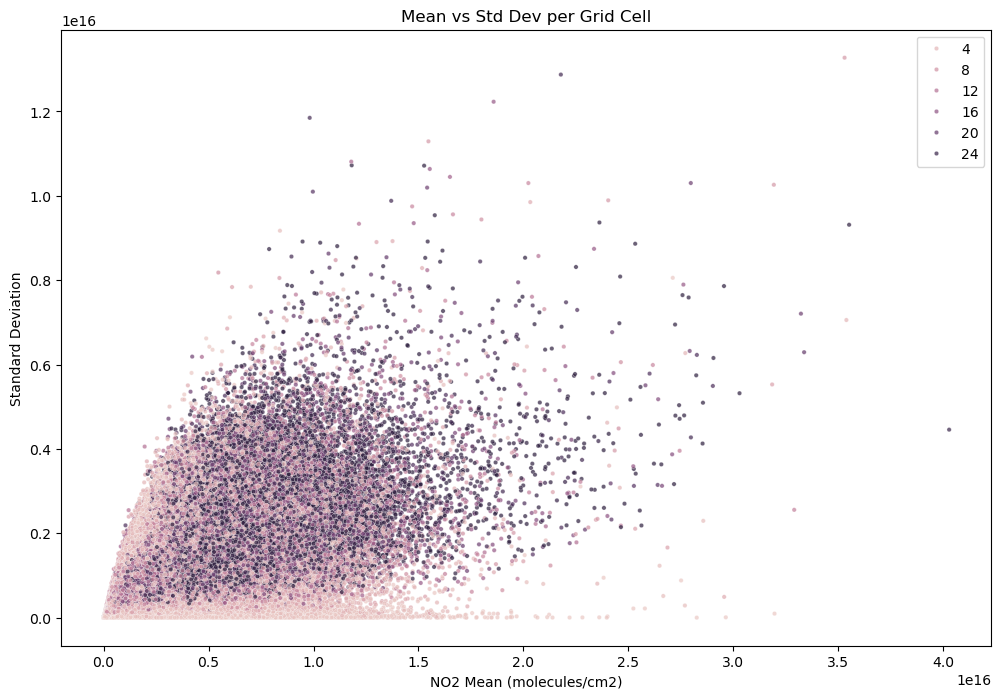

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,8))
sns.scatterplot(data=agg, x='no2_mean', y='no2_std', hue='no2_count', s=10, alpha=0.7)
plt.xlabel('NO2 Mean (molecules/cm2)')
plt.ylabel('Standard Deviation')
plt.legend()
plt.title('Mean vs Std Dev per Grid Cell')
plt.show()

/global/home/users/toireasamarie/.conda/envs/regrid_env2/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


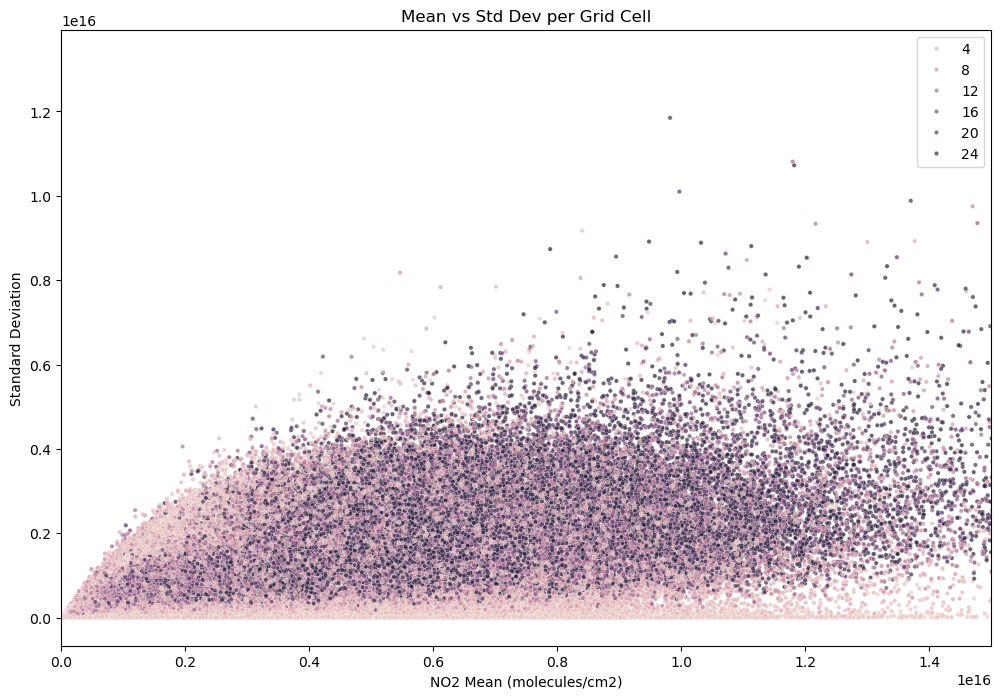

In [23]:
plt.figure(figsize=(12,8))
sns.scatterplot(data=agg, x='no2_mean', y='no2_std', hue='no2_count', s=10, alpha=0.7)
plt.xlabel('NO2 Mean (molecules/cm2)')
plt.xlim(0,1.5e16)
plt.ylabel('Standard Deviation')
plt.legend()
plt.title('Mean vs Std Dev per Grid Cell')
plt.show()

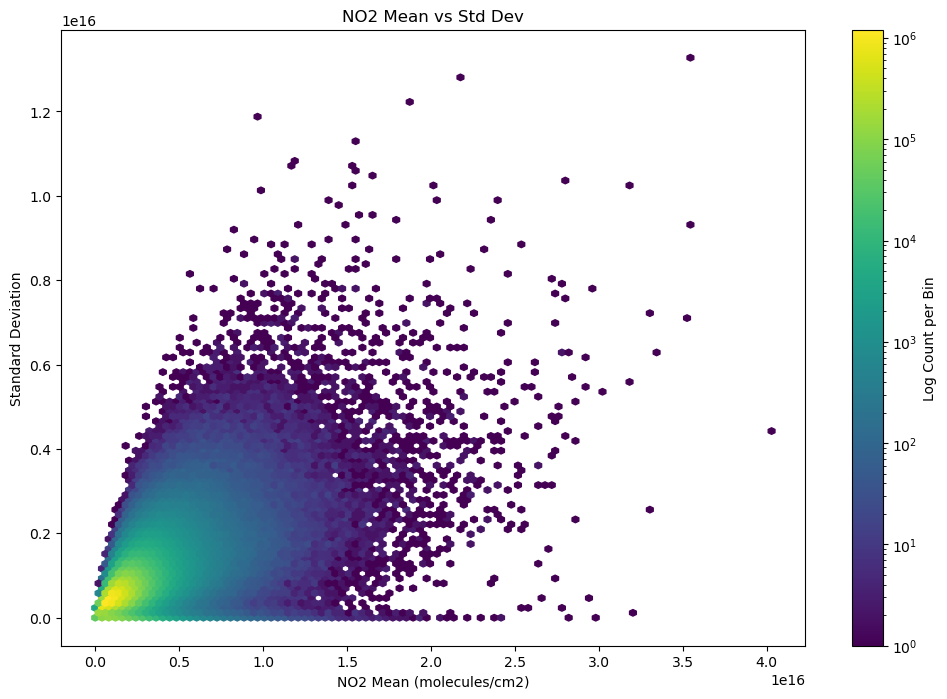

In [24]:
plt.figure(figsize=(12, 8))
hb = plt.hexbin(agg['no2_mean'], agg['no2_std'], gridsize=100, cmap='viridis', bins='log')
plt.colorbar(hb, label='Log Count per Bin')
plt.xlabel('NO2 Mean (molecules/cm2)')
plt.ylabel('Standard Deviation')
plt.title('NO2 Mean vs Std Dev')
plt.show()


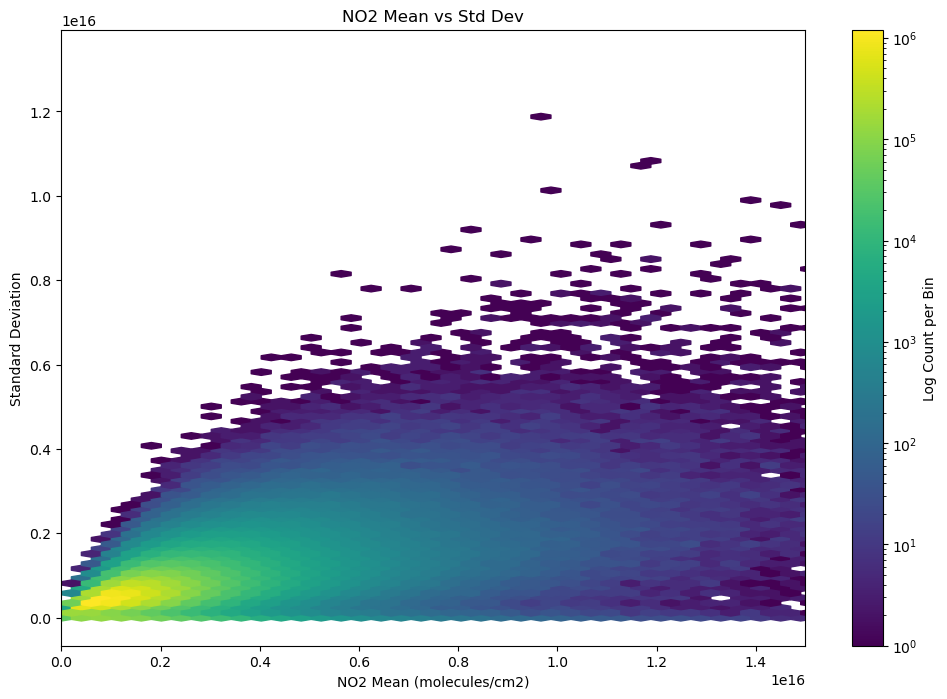

In [25]:
plt.figure(figsize=(12, 8))
hb = plt.hexbin(agg['no2_mean'], agg['no2_std'], gridsize=100, cmap='viridis', bins='log')
plt.colorbar(hb, label='Log Count per Bin')
plt.xlabel('NO2 Mean (molecules/cm2)')
plt.xlim(0, 1.5e16)
plt.ylabel('Standard Deviation')
plt.title('NO2 Mean vs Std Dev')
plt.show()


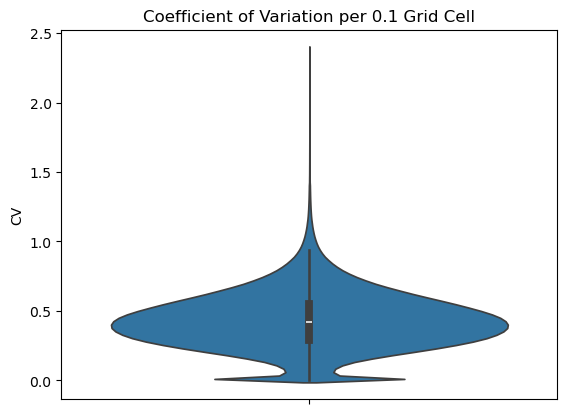

In [26]:
import matplotlib.pyplot as plt

sns.violinplot(data=agg, y='cv', inner='box')
plt.title('Coefficient of Variation per 0.1 Grid Cell')
plt.ylabel('CV')
plt.show()

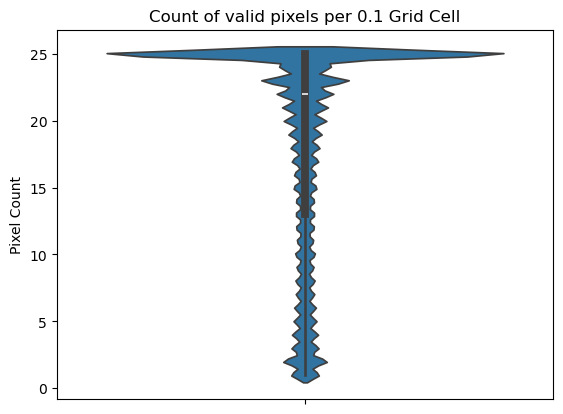

In [27]:
sns.violinplot(data=agg, y='no2_count', inner='box')
plt.title('Count of valid pixels per 0.1 Grid Cell')
plt.ylabel('Pixel Count')
plt.show()

In [26]:
agg

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv
0,2024-03-01 15:21:31.144745,35.049999,-119.650002,2.269577e+14,5.159870e+13,3,2.979052e+13,0.096850,0.004438,0.204974,0.005762,0.0,0.0,0.227349
1,2024-03-01 15:21:31.144745,35.049999,-119.549995,9.515827e+14,3.522849e+14,15,9.095956e+13,0.104091,0.029583,0.222151,0.059605,0.0,0.0,0.370209
2,2024-03-01 15:21:31.144745,35.049999,-119.449997,8.605737e+14,5.436859e+14,4,2.718429e+14,0.114695,0.038813,0.236052,0.074019,0.0,0.0,0.631771
3,2024-03-01 15:21:31.144745,35.049999,-119.349998,5.595516e+14,2.905847e+14,7,1.098307e+14,0.087362,0.013027,0.196908,0.030493,0.0,0.0,0.519317
4,2024-03-01 15:21:31.144745,35.049999,-119.250000,1.247359e+15,6.551548e+14,21,1.429665e+14,0.094297,0.014152,0.213727,0.029570,0.0,0.0,0.525233
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5240683,2024-07-31 23:33:15.152400,41.950001,-120.250000,6.602088e+14,1.881494e+14,8,6.652087e+13,0.135757,0.009042,0.451704,0.039769,0.0,0.0,0.284985
5240684,2024-07-31 23:33:15.152400,41.950001,-120.150002,6.736915e+14,3.229696e+14,2,2.283740e+14,0.143948,0.003130,0.496399,0.007531,0.0,0.0,0.479403
5240685,2024-07-31 23:33:15.152400,41.950001,-119.250000,1.022007e+15,3.055358e+14,19,7.009473e+13,0.138245,0.007662,0.477030,0.020453,0.0,0.0,0.298957
5240686,2024-07-31 23:33:15.152400,41.950001,-119.150002,1.221997e+15,4.481500e+14,15,1.157118e+14,0.137104,0.008446,0.467421,0.019819,0.0,0.0,0.366736


In [27]:
#need to make a condition where if have less than 12 no2_count, does not count as a valid pixel 

In [18]:
filtered_df = agg[agg['no2_count'] >= 13].copy()

In [19]:
filtered_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv
4,2024-03-01 13:41:26.146071,38.95,-80.05,8.335843e+14,3.157478e+14,16,7.893696e+13,0.090199,0.006510,0.284539,0.024910,0.0,0.0,0.378783
8,2024-03-01 13:41:26.146071,39.05,-80.05,1.055213e+15,5.102769e+14,20,1.141014e+14,0.092562,0.003461,0.297970,0.009242,0.0,0.0,0.483577
10,2024-03-01 13:41:26.146071,39.15,-81.25,1.277928e+15,6.824175e+14,15,1.761995e+14,0.094477,0.003371,0.291431,0.007734,0.0,0.0,0.534003
23,2024-03-01 13:41:26.146071,39.25,-80.35,2.177108e+15,1.002034e+15,14,2.678050e+14,0.095575,0.005012,0.297338,0.012624,0.0,0.0,0.460259
24,2024-03-01 13:41:26.146071,39.25,-80.25,1.692429e+15,1.336889e+15,17,3.242431e+14,0.094933,0.002528,0.296462,0.006289,0.0,0.0,0.789923
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17022643,2024-07-31 23:33:15.152400,44.85,-98.55,9.127368e+14,6.625882e+14,18,1.561735e+14,0.065685,0.015345,0.219664,0.043226,0.0,0.0,0.725936
17022654,2024-07-31 23:33:15.152400,47.55,-101.55,9.091537e+14,3.799678e+14,17,9.215573e+13,0.096196,0.002519,0.264359,0.005762,0.0,0.0,0.417936
17022655,2024-07-31 23:33:15.152400,47.55,-101.45,9.734493e+14,6.972724e+14,18,1.643487e+14,0.093640,0.002055,0.258643,0.005263,0.0,0.0,0.716290
17022656,2024-07-31 23:33:15.152400,47.55,-101.35,1.145534e+15,7.579429e+14,19,1.738840e+14,0.091976,0.002376,0.254564,0.005910,0.0,0.0,0.661650


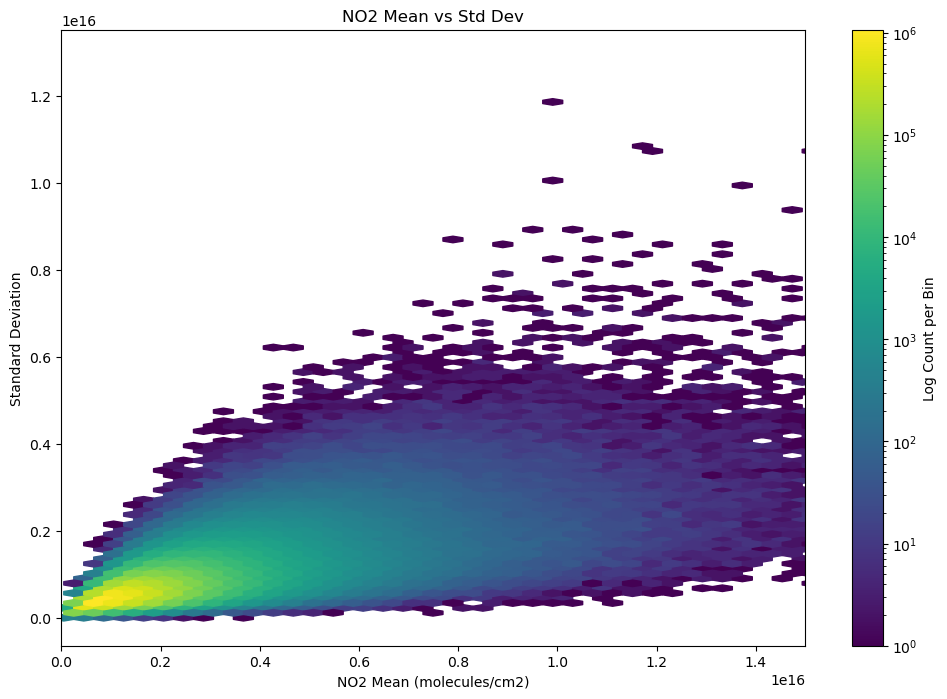

In [20]:
plt.figure(figsize=(12, 8))
hb = plt.hexbin(filtered_df['no2_mean'], filtered_df['no2_std'], gridsize=100, cmap='viridis', bins='log')
plt.colorbar(hb, label='Log Count per Bin')
plt.xlabel('NO2 Mean (molecules/cm2)')
plt.xlim(0, 1.5e16)
plt.ylabel('Standard Deviation')
plt.title('NO2 Mean vs Std Dev')
plt.show()


In [21]:
filtered_df= filtered_df.rename(columns={'cv':'cv_no2'})

In [22]:
output_parquet= '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/lowCF_TEMPO_0.1x0.1_gridded_mar-jul24.parquet'
filtered_df.to_parquet(output_parquet, engine='pyarrow')